# Baseline Model: Drăgulescu & Yakovenko (2000)

This notebook reproduces the monetary exchange model of Drăgulescu & Yakovenko (2000), the starting point for the rest of the project. Agents trade money in random pairwise exchanges and total money is conserved, much like energy in a gas of colliding particles. As a result, the stationary distribution of money is the exponential Boltzmann-Gibbs distribution.

The notebook also runs a "yard-sale" variant, where the amount exchanged depends on the wealth of the losing agent. Comparing the two shows how a small change to the exchange rule changes the shape of the distribution.

In [2]:
import numpy as np
from numpy import random
import matplotlib.pyplot as plt
from wealth_dist.plotting import plot_ccdf

np.random.seed()  # for reproducibility

### Theory (Drăgulescu \& Yakovenko, 2000)

With $N$ agents and total money $M$ conserved, the stationary distribution of money is exponential:

$ \textbf{Distribution}: p(m) = C e ^ {-m/T} \qquad C = 1/T, \quad T = M/N$

where the "temperature" $T$ is the average money per agent.

To track how the system approaches equilibrium, wealth is grouped into bins of unit width and the entropy of the distribution is computed after every exchange:

$ \textbf{Entropy}:
S = -\sum_{b=1}^{\infty} P_b \ln P_b,
\qquad P_b = N_b / N $

where $N_b$ is the number of agents in bin $b$. The entropy should rise and then level off once the distribution reaches equilibrium.

### Simulation

All agents start with the same amount of money $m$, so total money is $M = Nm$. At each step:
- Pick two distinct agents uniformly at random: agent $i$ wins and agent $j$ loses.
- Draw the amount exchanged, $\Delta m$:
    - **DY model** (`YS = False`): $\Delta m \sim U(0, m)$, independent of the agents' wealth.
    - **Yard-sale variant** (`YS = True`): $\Delta m \sim U(0, m_j)$, a random fraction of the loser's wealth.
- If the loser can afford it ($m_j \ge \Delta m$), transfer the money: $m_i \rightarrow m_i + \Delta m$ and $m_j \rightarrow m_j - \Delta m$. This ensures no debt.

`plot_simple` runs the simulation and plots the final wealth histogram next to the entropy over time. For the DY model, it also overlays the theoretical exponential distribution.

In [3]:
def plot_simple(N, m, sims, YS = False, res = False):

    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    bin_edges = np.linspace(0, 10000, 10001) #hardcoded, can be changed
    wealth = np.ones(N) * m 
    T = m
    C = 1/T
    entropy = []

    for k in range(sims):

        #wealth exchange
        i, j = random.choice(N, size=2, replace=False) 
        if YS:
            dm = np.random.uniform(0, wealth[j]) 
        else:
            dm = np.random.uniform(0, m) 

        if wealth[j] >= dm:
            wealth[i] += dm
            wealth[j] += -dm
        
        #entropy calculations
        vec, _ = np.histogram(wealth, bins = bin_edges)
        vec = vec[vec != 0] #problems with log 0 and less computation
        Pb = vec/N
        entropy.append(-np.sum(Pb*np.log(Pb)))

    axs[0].hist(wealth, bins = 50, density=True, label = 'Simulated')
    axs[0].set_title(f"Wealth Distributions after {sims} simulations")
    axs[0].set_xlabel("Wealth")
    axs[0].set_ylabel("Percentage of Agents")
    axs[1].plot(np.linspace(0, sims, sims), entropy)
    axs[1].set_xlabel("Simulations")
    axs[1].set_ylabel("Entropy")
    xvals = np.linspace(0, wealth.max(), sims)
    if not YS:
        axs[0].plot(xvals, C * np.exp(-xvals/T), label = 'Theoretical Exponential')
        axs[0].legend(loc='center right', fontsize='small')
    plt.show()

    if res:
        return wealth

### DY model

Run with $N = 1000$ agents, $m = 100$ and $10^4$ exchanges. The CCDF of the final wealth is then plotted with a logarithmic y-axis. For an exponential distribution, $P(W > w) = e^{-w/T}$, so the CCDF should appear as a straight line.

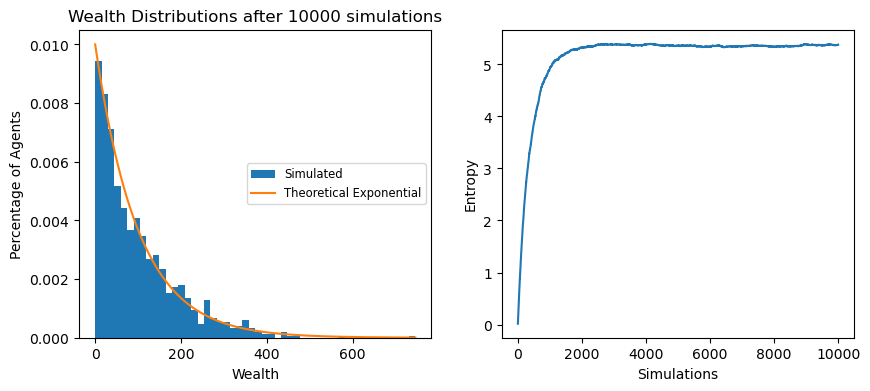

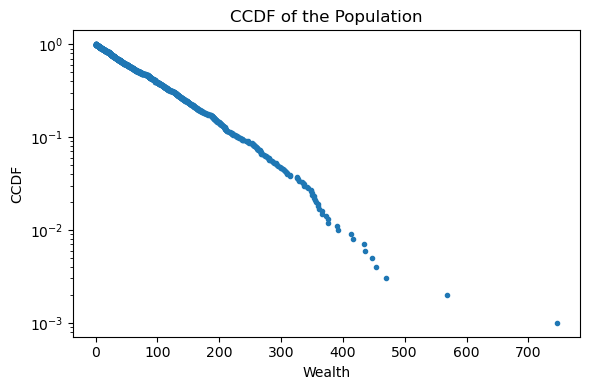

In [4]:
results = plot_simple(1000, 100, 10000, YS = False, res = True)
plot_ccdf(results, xlog = False, ylog = True)

The simulated histogram closely follows the theoretical exponential, and the CCDF is close to a straight line on the semi-log plot, as expected. The entropy rises quickly and levels off after about 2000 exchanges, showing that the system has reached equilibrium.

### Yard-sale variant

The same simulation is now run with the amount exchanged set by the loser's wealth. The exponential result no longer applies, so no theoretical curve is overlaid.

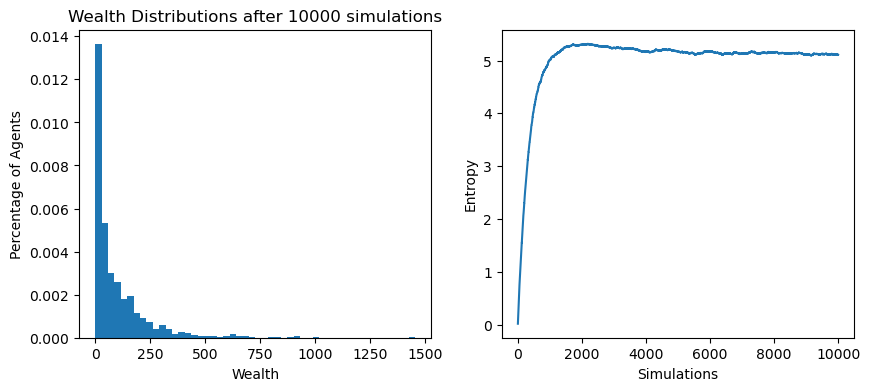

In [5]:
plot_simple(1000, 100, 10000, YS = True, res = False)

Compared with the DY model, more agents end up close to zero wealth and the tail stretches much further (up to about 1400, against about 650 for the DY model). The entropy also peaks and then slowly declines instead of levelling off, which suggests that wealth is gradually concentrating in fewer hands rather than settling into an equilibrium.

The exchange rule alone is therefore enough to change the shape of the distribution. The following notebooks build on this: `02_MGP.ipynb` adds aggregates to the DY model, and the later notebooks introduce new exchange mechanisms in search of a Pareto tail.